CUDA: Checking availability of GPU

In [51]:
import torch
import numpy as np

# check if CUDA is available
train_on_gpu = torch.cuda.is_available()

if not train_on_gpu:
  print('CUDA is not available.  Training on CPU ...')
else:
  print('CUDA is available!  Training on GPU ...')

CUDA is available!  Training on GPU ...


In [52]:
from torchvision.datasets import CIFAR100
from torchvision.transforms import ToTensor

In [53]:
TRAIN_DATASET = CIFAR100(root="data", train=True, download=True, transform=ToTensor())
TEST_DATASET = CIFAR100(root="data", train=False, download=True, transform=ToTensor())

In [19]:
class_names=TRAIN_DATASET.classes
print(class_names)
print(len(class_names))

['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider', 'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 'tractor', 'train', 'trout', 'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree',

In [20]:
print(f"Số lượng ảnh tập Train: {len(TRAIN_DATASET)}")
print(f"Số lượng ảnh tập Test: {len(TEST_DATASET)}")

image, label = TRAIN_DATASET[0]
print(f"Kiểu dữ liệu của ảnh: {type(image)}")
print(f"Kích thước của ảnh (Channels, Height, Width): {image.shape}")
print(f"Nhãn của ảnh (Index): {label}")

Số lượng ảnh tập Train: 50000
Số lượng ảnh tập Test: 10000
Kiểu dữ liệu của ảnh: <class 'torch.Tensor'>
Kích thước của ảnh (Channels, Height, Width): torch.Size([3, 32, 32])
Nhãn của ảnh (Index): 19


Visualizing the Data

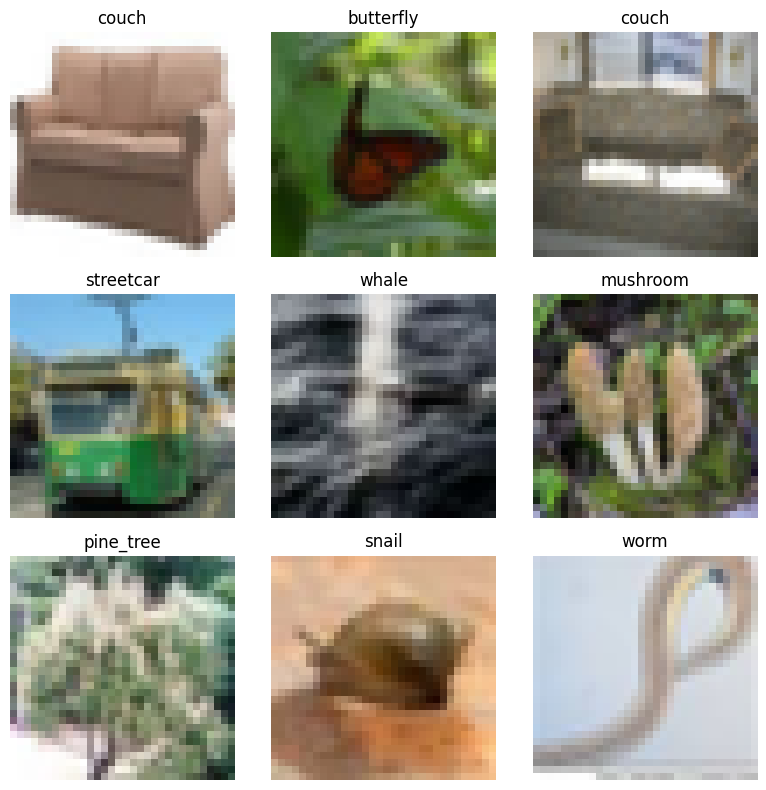

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Tạo khung hình 3x3
fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    # Chọn ngẫu nhiên một chỉ mục ảnh
    idx = np.random.randint(len(TRAIN_DATASET))
    img, lbl = TRAIN_DATASET[idx]
    
    # Chuyển đổi tensor [C, H, W] -> numpy [H, W, C] để vẽ
    img_np = img.permute(1, 2, 0).numpy()
    
    ax.imshow(img_np)
    ax.set_title(class_names[lbl])
    ax.axis('off')

plt.tight_layout()
plt.show()

View an Image in More Detail

Tổng số lớp check được: 100
Số lượng ảnh ít nhất ở một lớp: 500
Số lượng ảnh nhiều nhất ở một lớp: 500
==> KẾT LUẬN: Tập dữ liệu cân bằng hoàn hảo! Mỗi lớp có chính xác 500 ảnh.


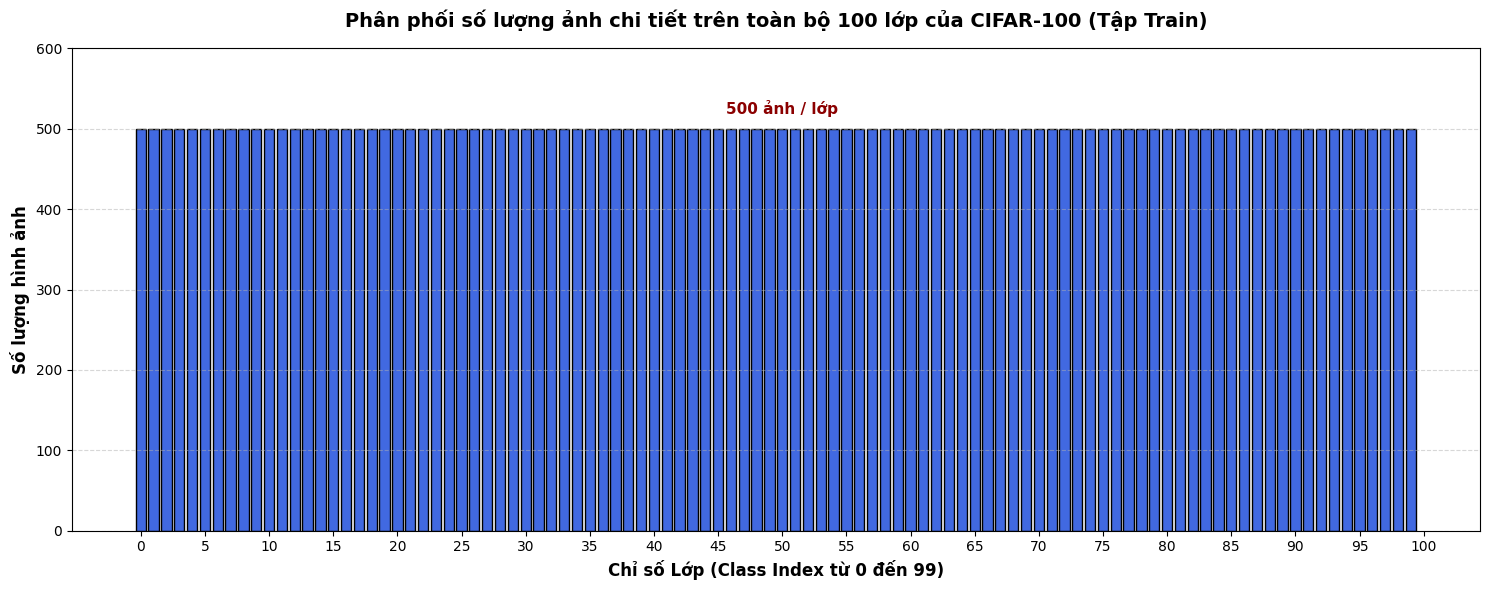

In [54]:
from collections import Counter

# 1. Đếm số lượng ảnh trong từng lớp từ dữ liệu thực tế
train_labels = TRAIN_DATASET.targets
class_names = TRAIN_DATASET.classes
class_counts = Counter(train_labels)

# Tạo danh sách số lượng sắp xếp theo đúng thứ tự index từ lớp 0 đến lớp 99
counts_all_classes = [class_counts[i] for i in range(100)]

# 2. Kiểm tra nhanh bằng mã lệnh
min_count = min(counts_all_classes)
max_count = max(counts_all_classes)
print(f"Tổng số lớp check được: {len(counts_all_classes)}")
print(f"Số lượng ảnh ít nhất ở một lớp: {min_count}")
print(f"Số lượng ảnh nhiều nhất ở một lớp: {max_count}")

if min_count == max_count:
    print(f"==> KẾT LUẬN: Tập dữ liệu cân bằng hoàn hảo! Mỗi lớp có chính xác {min_count} ảnh.")
else:
    print("==> KẾT LUẬN: Tập dữ liệu có sự chênh lệch giữa các lớp.")

# 3. Vẽ biểu đồ phân phối cho TOÀN BỘ 100 lớp
plt.figure(figsize=(15, 6))

# Sử dụng biểu đồ cột (bar chart) với độ rộng cột sát nhau để hiển thị toàn bộ 100 lớp
bars = plt.bar(range(100), counts_all_classes, color='royalblue', edgecolor='black', width=0.8)

# Cấu hình các trục và nhãn
plt.xlabel('Chỉ số Lớp (Class Index từ 0 đến 99)', fontsize=12, fontweight='bold')
plt.ylabel('Số lượng hình ảnh', fontsize=12, fontweight='bold')
plt.title('Phân phối số lượng ảnh chi tiết trên toàn bộ 100 lớp của CIFAR-100 (Tập Train)', fontsize=14, fontweight='bold', pad=15)

# Đặt vạch chia cho trục X cách mỗi 5 hoặc 10 đơn vị để biểu đồ thoáng, dễ nhìn
plt.xticks(np.arange(0, 101, 5)) 
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Đặt giới hạn trục Y cao hơn một chút so với giá trị 500 để biểu đồ đẹp hơn
plt.ylim(0, max_count + 100)

# Hiển thị số lượng lên đỉnh một vài cột đại diện để trực quan
plt.text(50, max_count + 15, f'{min_count} ảnh / lớp', ha='center', va='bottom', color='darkred', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


Tổng số lớp kiểm tra: 100
Số lượng ảnh ít nhất ở một lớp (Test): 100
Số lượng ảnh nhiều nhất ở một lớp (Test): 100
==> KẾT LUẬN: Tập Test cân bằng hoàn hảo! Mỗi lớp có chính xác 100 ảnh.


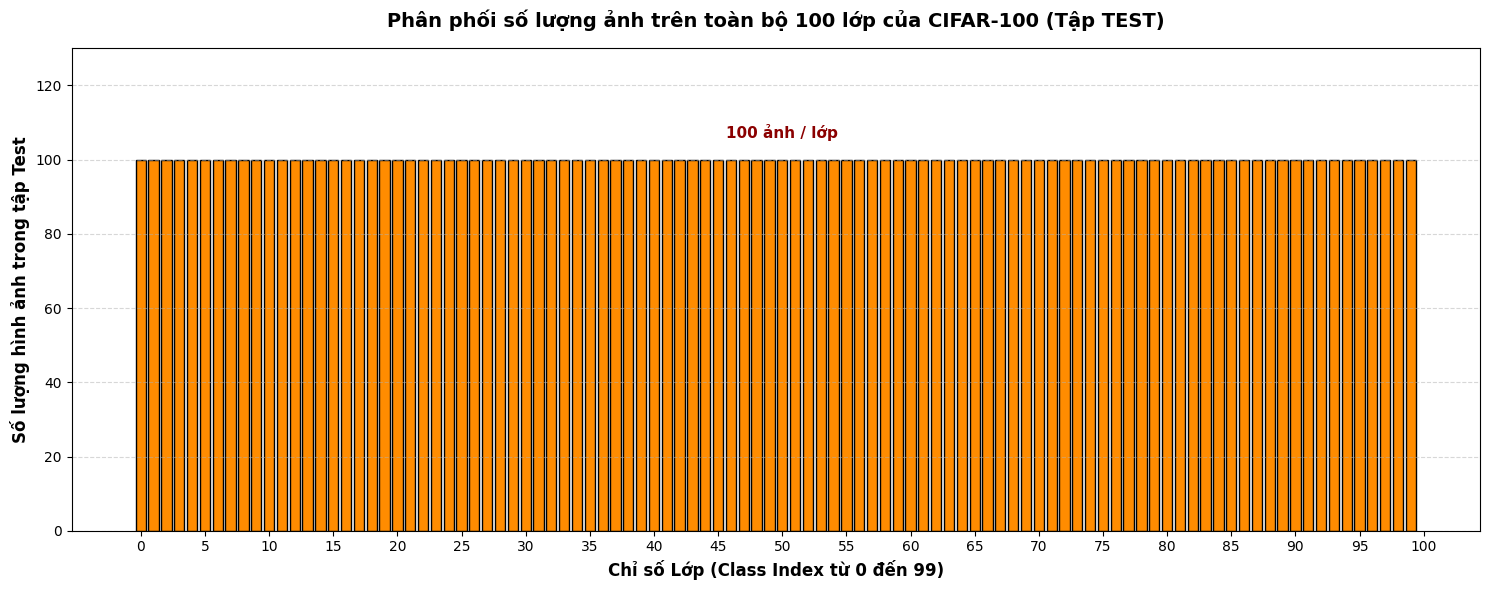

In [24]:
test_labels = TEST_DATASET.targets
test_class_names = TEST_DATASET.classes
test_class_counts = Counter(test_labels)

# Tạo danh sách số lượng sắp xếp theo đúng thứ tự index từ lớp 0 đến lớp 99
counts_all_test_classes = [test_class_counts[i] for i in range(100)]

# 2. Kiểm tra nhanh bằng mã lệnh
min_test_count = min(counts_all_test_classes)
max_test_count = max(counts_all_test_classes)
print(f"Tổng số lớp kiểm tra: {len(counts_all_test_classes)}")
print(f"Số lượng ảnh ít nhất ở một lớp (Test): {min_test_count}")
print(f"Số lượng ảnh nhiều nhất ở một lớp (Test): {max_test_count}")

if min_test_count == max_test_count:
    print(f"==> KẾT LUẬN: Tập Test cân bằng hoàn hảo! Mỗi lớp có chính xác {min_test_count} ảnh.")
else:
    print("==> KẾT LUẬN: Tập Test có sự chênh lệch số lượng giữa các lớp.")

# 3. Vẽ biểu đồ phân phối cho TOÀN BỘ 100 lớp của tập Test
plt.figure(figsize=(15, 6))

# Sử dụng biểu đồ cột với màu cam đặc trưng cho tập Test (phân biệt với màu xanh của tập Train)
plt.bar(range(100), counts_all_test_classes, color='darkorange', edgecolor='black', width=0.8)

# Cấu hình các trục và nhãn biểu đồ
plt.xlabel('Chỉ số Lớp (Class Index từ 0 đến 99)', fontsize=12, fontweight='bold')
plt.ylabel('Số lượng hình ảnh trong tập Test', fontsize=12, fontweight='bold')
plt.title('Phân phối số lượng ảnh trên toàn bộ 100 lớp của CIFAR-100 (Tập TEST)', fontsize=14, fontweight='bold', pad=15)

# Đặt vạch chia cho trục X cách mỗi 5 hoặc 10 đơn vị để dễ nhìn
plt.xticks(np.arange(0, 101, 5)) 
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Giới hạn trục Y cao hơn 100 một chút để biểu đồ thoáng đãng
plt.ylim(0, max_test_count + 30)

# Hiển thị text ghi chú số lượng lên giữa biểu đồ để trực quan nhanh
plt.text(50, max_test_count + 5, f'{min_test_count} ảnh / lớp', ha='center', va='bottom', color='darkred', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

Tính giá trị mean và std của bộ dữ liệu

In [55]:
# Chuyển toàn bộ dữ liệu ảnh thành một Tensor lớn duy nhất
# Kích thước ban đầu của mỗi ảnh là, xếp chồng 50.000 ảnh lại
all_images = torch.stack([img for img, _ in TRAIN_DATASET], dim=0)

# Tính Mean và Std dọc theo các kênh màu (dim=0, 2, 3 tương ứng với N, H, W)
calculated_mean = all_images.mean(dim=[0, 2, 3])
calculated_std = all_images.std(dim=[0, 2, 3])

print("Kết quả tính toán trực tiếp từ dữ liệu:")
print(f" - Mean từng kênh: {calculated_mean.tolist()}")
print(f" - Std từng kênh:  {calculated_std.tolist()}")

Kết quả tính toán trực tiếp từ dữ liệu:
 - Mean từng kênh: [0.5070757865905762, 0.48655030131340027, 0.4409191310405731]
 - Std từng kênh:  [0.2673342823982239, 0.2564384639263153, 0.2761504650115967]


In [56]:
from torchvision import transforms
# Chuyển đổi Tensor kết quả thành danh sách số thực (List of floats)
pixel_mean = calculated_mean.tolist()
pixel_std = calculated_std.tolist()

# Đảm bảo pixel_mean và pixel_std là danh sách hoặc tuple gồm 3 phần tử 

dynamic_transform = transforms.Compose([
    transforms.ToTensor(),
    # Truyền trực tiếp danh sách/tuple 3 kênh vào, KHÔNG thêm dấu phẩy ở cuối
    transforms.Normalize(mean=pixel_mean, std=pixel_std)
])
#Áp dụng transform động này vào tập dữ liệu thực tế dùng để Train và Test
FINAL_TRAIN_DATASET = CIFAR100(root="data", train=True, download=True, transform=dynamic_transform)
FINAL_TEST_DATASET  = CIFAR100(root="data", train=False, download=True, transform=dynamic_transform)

Chia tập huấn luyện thành 90% (Train) và 10% (Validation) một cách ngẫu nhiên(suffle)

In [57]:
from torch.utils.data import random_split, DataLoader

# 1. Xác định kích thước cho tập Train (90%) và Validation (10%)
total_train_samples = len(FINAL_TRAIN_DATASET)
train_size = int(0.9 * total_train_samples)         # 90% của 50.000 = 45.000 ảnh
val_size = total_train_samples - train_size         # 10% còn lại = 5.000 ảnh

# Thiết lập bộ sinh số ngẫu nhiên (seed) để kết quả chia tách có thể tái lập lại được
generator = torch.Generator().manual_seed(42)

# 2. Thực hiện chia tách dữ liệu ngẫu nhiên (Tự động trộn/shuffle dữ liệu trước khi chia)
TRAIN_SUBSET, VAL_SUBSET = random_split(
    FINAL_TRAIN_DATASET, 
    [train_size, val_size], 
    generator=generator
)

print(f"Số lượng ảnh tập Train mới: {len(TRAIN_SUBSET)}")
print(f"Số lượng ảnh tập Validation: {len(VAL_SUBSET)}")
print(f"Số lượng ảnh tập Test (giữ nguyên): {len(FINAL_TEST_DATASET)}")

# 3. Khởi tạo các DataLoader để nạp dữ liệu vào mô hình
BATCH_SIZE = 64 # có thể đổi thành 128 hoặc 256 tùy dung lượng GPU

# Tập Train: Cần shuffle=True để xáo trộn dữ liệu sau mỗi Epoch
train_loader = DataLoader(TRAIN_SUBSET, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)

# Tập Validation và Test: Tuyệt đối KHÔNG shuffle (để shuffle=False) nhằm đánh giá mô hình khách quan
val_loader = DataLoader(VAL_SUBSET, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(FINAL_TEST_DATASET, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

Số lượng ảnh tập Train mới: 45000
Số lượng ảnh tập Validation: 5000
Số lượng ảnh tập Test (giữ nguyên): 10000


Defining the Network Architecture

In [58]:
import torch.nn as nn
import torch.nn.functional as F

In [59]:
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super(BasicBlock, self).__init__()
        # Lớp Convolution thứ nhất
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        
        # Lớp Convolution thứ hai
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Đường tắt (Shortcut connection)
        self.shortcut = nn.Sequential()
        # Nếu kích thước ảnh hoặc số kênh thay đổi, đường tắt cần dùng Conv 1x1 để điều chỉnh kích thước
        if stride != 1 or in_channels != self.expansion * out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, self.expansion * out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(self.expansion * out_channels)
            )

    def forward(self, x):
        # Nhánh chính
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        
        # Cộng nhánh chính với đường tắt (Skip Connection)
        out += self.shortcut(x)
        out = F.relu(out)
        return out


In [60]:
class ResNet18_CIFAR(nn.Module):
    def __init__(self, num_classes=100):
        super(ResNet18_CIFAR, self).__init__()
        self.in_channels = 64

        # Lớp Conv đầu vào được tối ưu cho ảnh CIFAR (32x32)
        # Thay vì dùng kernel 7x7 stride 2 của ImageNet, ta dùng 3x3 stride 1 để giữ chi tiết ảnh nhỏ
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        
        # 4 Layer chính của ResNet-18 (Mỗi layer chứa 2 khối BasicBlock)
        self.layer1 = self._make_layer(BasicBlock, 64, num_blocks=2, stride=1)
        self.layer2 = self._make_layer(BasicBlock, 128, num_blocks=2, stride=2)
        self.layer3 = self._make_layer(BasicBlock, 256, num_blocks=2, stride=2)
        self.layer4 = self._make_layer(BasicBlock, 512, num_blocks=2, stride=2)
        
        # Lớp phân loại đầu ra (Linear layer cho 100 lớp của CIFAR-100)
        self.linear = nn.Linear(512 * BasicBlock.expansion, num_classes)

    def _make_layer(self, block, out_channels, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1) # Ví dụ: [2, 1] cho layer cần giảm kích thước ảnh
        layers = []
        for stride in strides:
            layers.append(block(self.in_channels, out_channels, stride))
            self.in_channels = out_channels * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x):
        # Đầu vào: [Batch, 3, 32, 32]
        out = F.relu(self.bn1(self.conv1(x))) # Kích thước vẫn giữ: [Batch, 64, 32, 32]
        
        # Đi qua các khối Residual Block
        out = self.layer1(out) # [Batch, 64, 32, 32]
        out = self.layer2(out) # [Batch, 128, 16, 16]
        out = self.layer3(out) # [Batch, 256, 8, 8]
        out = self.layer4(out) # [Batch, 512, 4, 4]
        
        # Lớp Global Average Pooling (Thay thế AdaptiveAvgPool2d bằng F.avg_pool2d cho ảnh 4x4)
        out = F.avg_pool2d(out, 4) # [Batch, 512, 1, 1]
        out = out.view(out.size(0), -1) # Phẳng hóa (Flatten) thành [Batch, 512]
        
        # Phân loại
        out = self.linear(out) # Đầu ra: [Batch, 100]
        return out


Test thử trước khi chạy chính thức

In [37]:
# Khởi tạo mô hình
model = ResNet18_CIFAR(num_classes=100)

# Đẩy mô hình lên GPU nếu có
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Tạo tensor giả lập 1 Batch gồm 4 ảnh CIFAR-100 (3 kênh, 32x32)
dummy_input = torch.randn(4, 3, 32, 32).to(device)

# Chạy thử forward pass
output = model(dummy_input)

print(f"Thiết bị đang chạy: {device}")
print(f"Kích thước tensor đầu vào: {dummy_input.shape}")
print(f"Kích thước tensor đầu ra:  {output.shape}") 
# Kết quả kỳ vọng sẽ là torch.Size([4, 100])


Thiết bị đang chạy: cuda
Kích thước tensor đầu vào: torch.Size([4, 3, 32, 32])
Kích thước tensor đầu ra:  torch.Size([4, 100])


In [38]:
import torch.optim as optim

# 2. Khởi tạo Hàm lỗi (Loss Function)
criterion = nn.CrossEntropyLoss()

# 3. Khởi tạo Optimizer
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)

scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=35, gamma=0.2)


In [41]:
import time

# Cấu hình số Epoch huấn luyện
EPOCHS = 100
best_val_acc = 0.0  # Biến lưu độ chính xác cao nhất để lưu checkpoint

# BỔ SUNG: Khởi tạo các danh sách trống để lưu lại dữ liệu phục vụ visualization
history_train_loss = []
history_val_loss = []
history_train_acc = []
history_val_acc = []

print("Bắt đầu quá trình huấn luyện...")

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    
    # ------------------- PHA HUẤN LUYỆN (TRAINING PHASE) -------------------
    model.train()  # Chuyển mô hình sang chế độ train
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()
        
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = 100.0 * train_correct / train_total

    # ------------------- PHA XÁC THỰC (VALIDATION PHASE) -------------------
    model.eval()  # Chuyển mô hình sang chế độ đánh giá
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = 100.0 * val_correct / val_total
    
    # BỔ SUNG: Lưu các chỉ số trung bình của epoch hiện tại vào lịch sử
    history_train_loss.append(epoch_train_loss)
    history_val_loss.append(epoch_val_loss)
    history_train_acc.append(epoch_train_acc)
    history_val_acc.append(epoch_val_acc)
    
    # ------------------- CẬP NHẬT LEARNING RATE -------------------
    current_lr = optimizer.param_groups[0]['lr']
    scheduler.step()  # Cập nhật LR theo cấu hình StepLR
    
    epoch_time = time.time() - start_time
    
    # ------------------- IN KẾT QUẢ & LƯU CHECKPOINT -------------------
    print(f"Epoch [{epoch}/{EPOCHS}] ({epoch_time:.1f}s) | LR: {current_lr:.5f}")
    print(f"  > Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%")
    print(f"  > Val Loss:   {epoch_val_loss:.4f} | Val Acc:   {epoch_val_acc:.2f}%")
    
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), 'best_resnet18_cifar100.pth')
        print(f"   Đã lưu mô hình tốt nhất mới với Val Acc: {best_val_acc:.2f}%")
    print("-" * 60)

print(f"\nHuấn luyện hoàn tất! Độ chính xác Validation tốt nhất đạt được: {best_val_acc:.2f}%")


Bắt đầu quá trình huấn luyện...
Epoch [1/100] (92.8s) | LR: 0.10000
  > Train Loss: 1.5338 | Train Acc: 56.85%
  > Val Loss:   2.2373 | Val Acc:   42.88%
   Đã lưu mô hình tốt nhất mới với Val Acc: 42.88%
------------------------------------------------------------
Epoch [2/100] (92.6s) | LR: 0.10000
  > Train Loss: 1.4507 | Train Acc: 58.63%
  > Val Loss:   2.1031 | Val Acc:   46.60%
   Đã lưu mô hình tốt nhất mới với Val Acc: 46.60%
------------------------------------------------------------
Epoch [3/100] (92.4s) | LR: 0.10000
  > Train Loss: 1.3779 | Train Acc: 60.72%
  > Val Loss:   2.1119 | Val Acc:   46.36%
------------------------------------------------------------
Epoch [4/100] (92.6s) | LR: 0.10000
  > Train Loss: 1.3265 | Train Acc: 61.88%
  > Val Loss:   2.2325 | Val Acc:   44.58%
------------------------------------------------------------
Epoch [5/100] (87.4s) | LR: 0.10000
  > Train Loss: 1.2766 | Train Acc: 63.28%
  > Val Loss:   2.1125 | Val Acc:   46.82%
   Đã lưu mô

In [42]:
import json

# 1. Tải lại trọng số tốt nhất trước khi test
model.load_state_dict(torch.load('best_resnet18_cifar100.pth'))
model.eval()

y_true = []
y_pred = []

# 2. Đánh giá trên tập TEST để lấy nhãn phục vụ Confusion Matrix
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        
        y_true.extend(labels.numpy().tolist()) # Chuyển sang list để lưu được JSON
        y_pred.extend(predicted.cpu().numpy().tolist())

# 3. Đóng gói toàn bộ dữ liệu vào một Dictionary
log_data = {
    "history_train_loss": history_train_loss,
    "history_val_loss": history_val_loss,
    "history_train_acc": history_train_acc,
    "history_val_acc": history_val_acc,
    "y_true": y_true,
    "y_pred": y_pred
}

# 4. Ghi dữ liệu vào file JSON
with open('training_logs.json', 'w') as f:
    json.dump(log_data, f)

print("Đã lưu thành công toàn bộ dữ liệu huấn luyện và dự đoán vào file 'training_logs.json'!")


Đã lưu thành công toàn bộ dữ liệu huấn luyện và dự đoán vào file 'training_logs.json'!


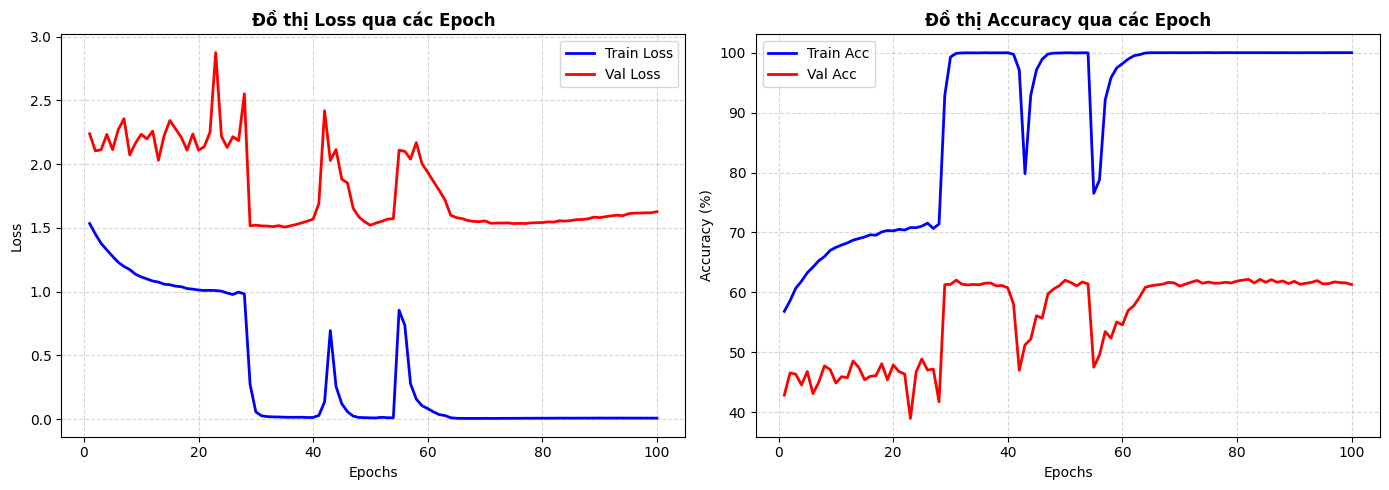

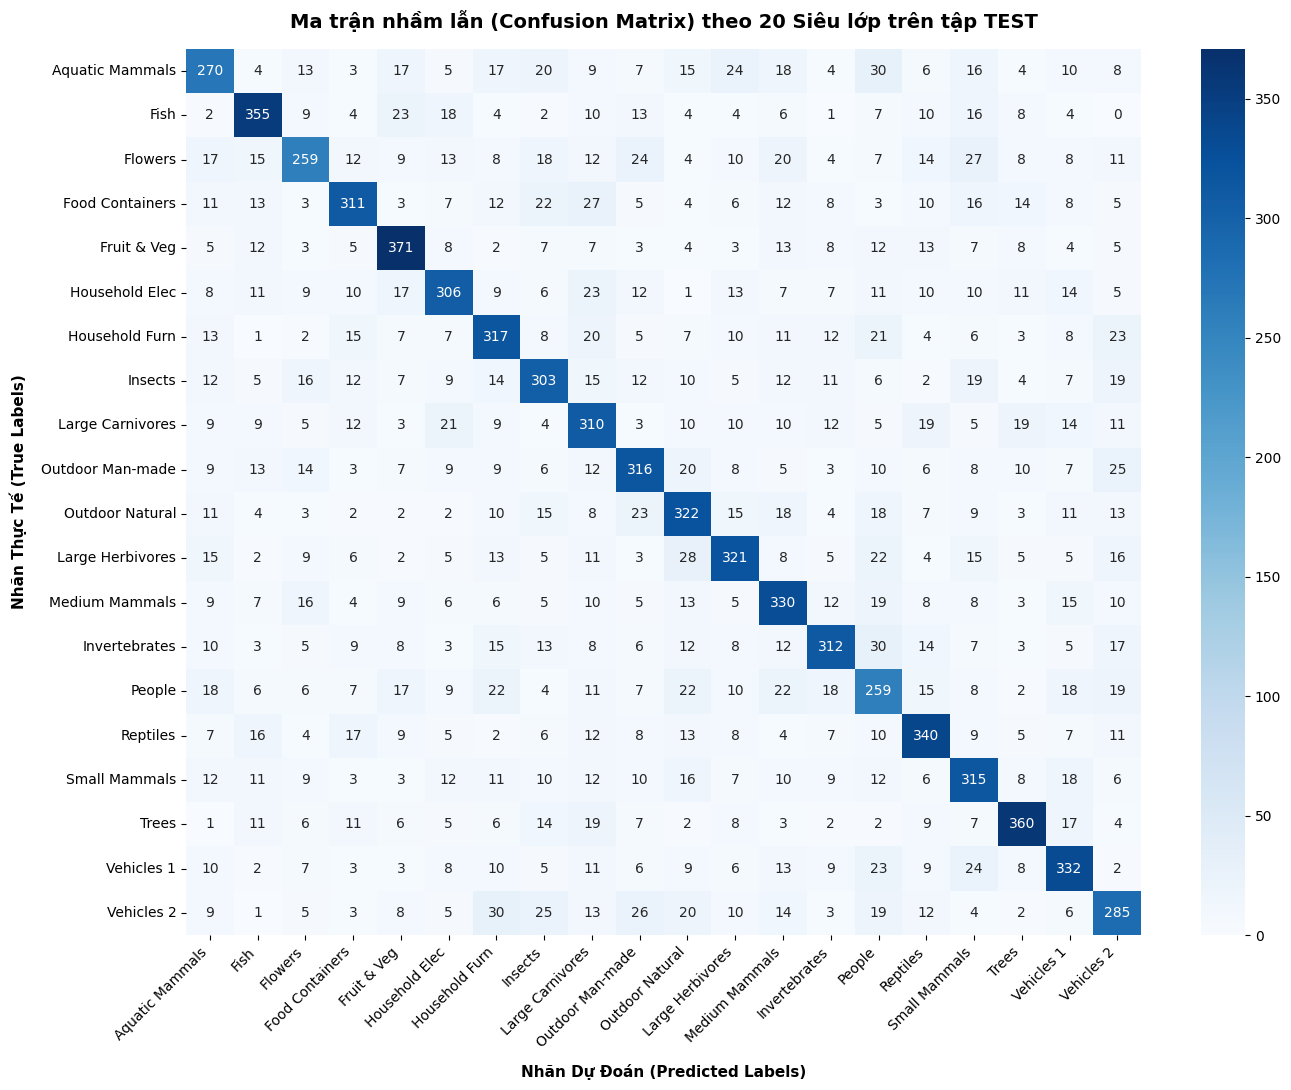

In [43]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Đọc dữ liệu từ file JSON
with open('training_logs.json', 'r') as f:
    data = json.load(f)

# Trích xuất dữ liệu lịch sử
train_loss = data["history_train_loss"]
val_loss = data["history_val_loss"]
train_acc = data["history_train_acc"]
val_acc = data["history_val_acc"]

# Trích xuất dữ liệu nhãn tập Test
y_true = np.array(data["y_true"])
y_pred = np.array(data["y_pred"])

epochs_range = range(1, len(train_loss) + 1)

# ==================== ĐỒ THỊ 1: LOSS & ACCURACY ====================
plt.figure(figsize=(14, 5))

# Đồ thị Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_loss, 'b-', label='Train Loss', linewidth=2)
plt.plot(epochs_range, val_loss, 'r-', label='Val Loss', linewidth=2)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Đồ thị Loss qua các Epoch', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# Đồ thị Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_acc, 'b-', label='Train Acc', linewidth=2)
plt.plot(epochs_range, val_acc, 'r-', label='Val Acc', linewidth=2)
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Đồ thị Accuracy qua các Epoch', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

# ==================== ĐỒ THỊ 2: MA TRẬN NHẦM LẪN (20 SIÊU LỚP) ====================
# Ánh xạ nhãn từ 100 lớp con về 20 siêu lớp bằng phép chia nguyên
y_true_coarse = y_true // 5
y_pred_coarse = y_pred // 5

# Danh sách tên 20 siêu lớp chuẩn của CIFAR-100
coarse_labels = [
    'Aquatic Mammals', 'Fish', 'Flowers', 'Food Containers', 'Fruit & Veg',
    'Household Elec', 'Household Furn', 'Insects', 'Large Carnivores', 'Outdoor Man-made',
    'Outdoor Natural', 'Large Herbivores', 'Medium Mammals', 'Invertebrates', 'People',
    'Reptiles', 'Small Mammals', 'Trees', 'Vehicles 1', 'Vehicles 2'
]

# Tính toán ma trận nhầm lẫn
cm = confusion_matrix(y_true_coarse, y_pred_coarse)

# Vẽ Heatmap
plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=coarse_labels, yticklabels=coarse_labels)
plt.xlabel('Nhãn Dự Đoán (Predicted Labels)', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Nhãn Thực Tế (True Labels)', fontsize=11, fontweight='bold', labelpad=10)
plt.title('Ma trận nhầm lẫn (Confusion Matrix) theo 20 Siêu lớp trên tập TEST', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


Agumentation 

In [61]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    # Bổ sung AutoAugment hoặc ColorJitter để thay đổi ngẫu nhiên độ sáng, độ tương phản
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=pixel_mean, std=pixel_std)
])

In [62]:
#Áp dụng transform động này vào tập dữ liệu thực tế dùng để Train và Test
FINAL_TRAIN_DATASET = CIFAR100(root="data", train=True, download=True, transform=dynamic_transform)
FINAL_TEST_DATASET  = CIFAR100(root="data", train=False, download=True, transform=dynamic_transform)

In [63]:
total_train_samples = len(FINAL_TRAIN_DATASET)
train_size = int(0.9 * total_train_samples)         # 90% của 50.000 = 45.000 ảnh
val_size = total_train_samples - train_size         # 10% còn lại = 5.000 ảnh

# Thiết lập bộ sinh số ngẫu nhiên (seed) để kết quả chia tách có thể tái lập lại được
generator = torch.Generator().manual_seed(42)

# 2. Thực hiện chia tách dữ liệu ngẫu nhiên (Tự động trộn/shuffle dữ liệu trước khi chia)
TRAIN_SUBSET, VAL_SUBSET = random_split(
    FINAL_TRAIN_DATASET, 
    [train_size, val_size], 
    generator=generator
)

# 3. Khởi tạo các DataLoader để nạp dữ liệu vào mô hình
BATCH_SIZE = 64 # có thể đổi thành 128 hoặc 256 tùy dung lượng GPU

# Tập Train: Cần shuffle=True để xáo trộn dữ liệu sau mỗi Epoch
train_loader = DataLoader(TRAIN_SUBSET, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)

# Tập Validation và Test: Tuyệt đối KHÔNG shuffle (để shuffle=False) nhằm đánh giá mô hình khách quan
val_loader = DataLoader(VAL_SUBSET, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(FINAL_TEST_DATASET, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

In [64]:
# 2. Khởi tạo Hàm lỗi (Loss Function)
criterion = nn.CrossEntropyLoss()

# 3. Khởi tạo Optimizer
optimizer = optim.SGD(model.parameters(), lr=0.02, momentum=0.9, weight_decay=5e-4)

scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=35, gamma=0.2)

In [65]:

# Cấu hình số Epoch huấn luyện
EPOCHS = 100
best_val_acc = 0.0  # Biến lưu độ chính xác cao nhất để lưu checkpoint

# BỔ SUNG: Khởi tạo các danh sách trống để lưu lại dữ liệu phục vụ visualization
history_train_loss = []
history_val_loss = []
history_train_acc = []
history_val_acc = []

print("Bắt đầu quá trình huấn luyện...")

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    
    # ------------------- PHA HUẤN LUYỆN (TRAINING PHASE) -------------------
    model.train()  # Chuyển mô hình sang chế độ train
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()
        
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = 100.0 * train_correct / train_total

    # ------------------- PHA XÁC THỰC (VALIDATION PHASE) -------------------
    model.eval()  # Chuyển mô hình sang chế độ đánh giá
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = 100.0 * val_correct / val_total
    
    # BỔ SUNG: Lưu các chỉ số trung bình của epoch hiện tại vào lịch sử
    history_train_loss.append(epoch_train_loss)
    history_val_loss.append(epoch_val_loss)
    history_train_acc.append(epoch_train_acc)
    history_val_acc.append(epoch_val_acc)
    
    # ------------------- CẬP NHẬT LEARNING RATE -------------------
    current_lr = optimizer.param_groups[0]['lr']
    scheduler.step()  # Cập nhật LR theo cấu hình StepLR
    
    epoch_time = time.time() - start_time
    
    # ------------------- IN KẾT QUẢ & LƯU CHECKPOINT -------------------
    print(f"Epoch [{epoch}/{EPOCHS}] ({epoch_time:.1f}s) | LR: {current_lr:.5f}")
    print(f"  > Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%")
    print(f"  > Val Loss:   {epoch_val_loss:.4f} | Val Acc:   {epoch_val_acc:.2f}%")
    
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), 'best_resnet18_cifar100.pth')
        print(f"   Đã lưu mô hình tốt nhất mới với Val Acc: {best_val_acc:.2f}%")
    print("-" * 60)

print(f"\nHuấn luyện hoàn tất! Độ chính xác Validation tốt nhất đạt được: {best_val_acc:.2f}%")


Bắt đầu quá trình huấn luyện...
Epoch [1/100] (20.0s) | LR: 0.02000
  > Train Loss: 1.1653 | Train Acc: 69.41%
  > Val Loss:   2.2479 | Val Acc:   43.66%
   Đã lưu mô hình tốt nhất mới với Val Acc: 43.66%
------------------------------------------------------------
Epoch [2/100] (19.8s) | LR: 0.02000
  > Train Loss: 1.1898 | Train Acc: 66.29%
  > Val Loss:   1.8186 | Val Acc:   53.52%
   Đã lưu mô hình tốt nhất mới với Val Acc: 53.52%
------------------------------------------------------------
Epoch [3/100] (19.8s) | LR: 0.02000
  > Train Loss: 0.6398 | Train Acc: 81.61%
  > Val Loss:   2.0008 | Val Acc:   52.02%
------------------------------------------------------------
Epoch [4/100] (19.8s) | LR: 0.02000
  > Train Loss: 0.3631 | Train Acc: 89.34%
  > Val Loss:   2.0929 | Val Acc:   52.72%
------------------------------------------------------------
Epoch [5/100] (19.8s) | LR: 0.02000
  > Train Loss: 0.2301 | Train Acc: 93.47%
  > Val Loss:   2.0877 | Val Acc:   53.64%
   Đã lưu mô

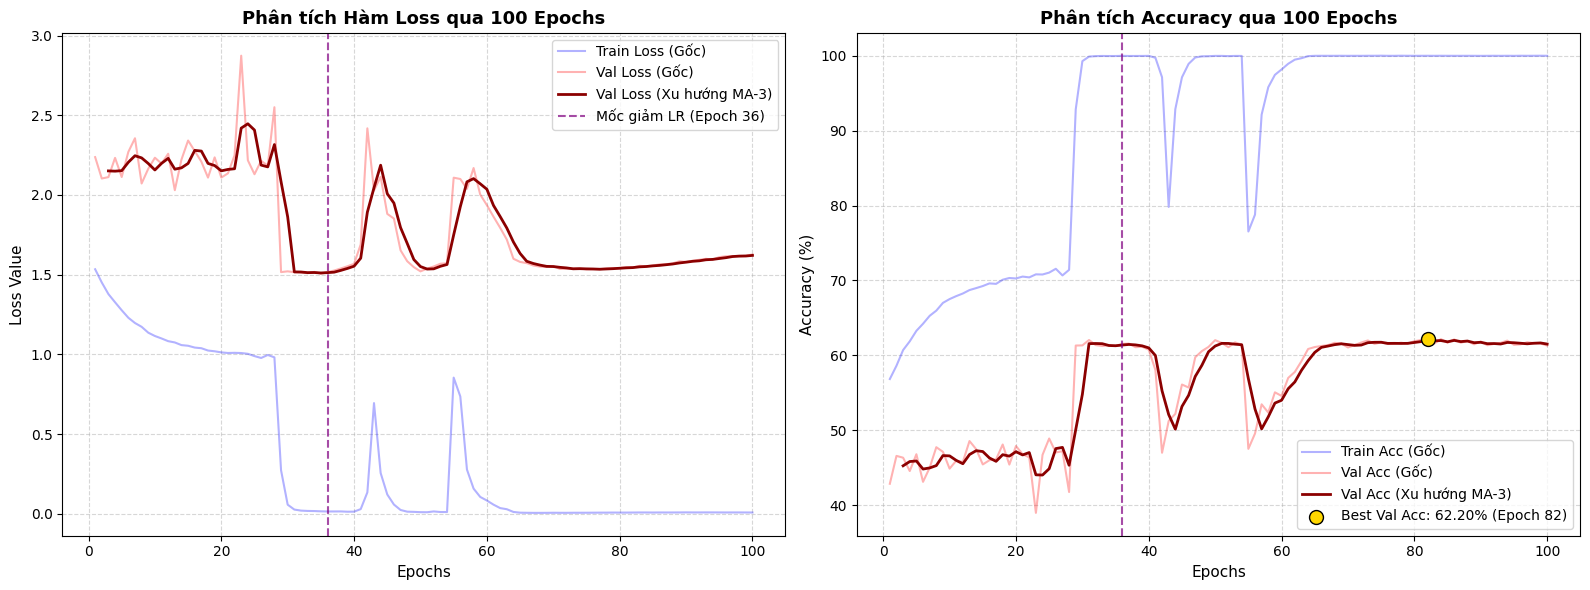

Đã lưu đồ thị hiệu năng vào file 'performance_charts.png'
Đã sao lưu bản sao log tăng cường vào file 'training_logs_augmented.json'


In [68]:
import json
# 1. Đọc dữ liệu từ file JSON
with open('training_logs.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

train_loss = data["history_train_loss"]
val_loss = data["history_val_loss"]
train_acc = data["history_train_acc"]
val_acc = data["history_val_acc"]
epochs_range = range(1, len(train_loss) + 1)

# Hàm tính toán Trung bình trượt (Moving Average) để làm mịn đường răng cưa
def moving_average(data_list, window_size=3):
    return np.convolve(data_list, np.ones(window_size)/window_size, mode='valid')

window = 3
ma_epochs = range(window, len(train_loss) + 1)
ma_val_loss = moving_average(val_loss, window_size=window)
ma_val_acc = moving_average(val_acc, window_size=window)

plt.figure(figsize=(16, 6))

# --- BIỂU ĐỒ HÀM LOSS ---
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_loss, color='blue', alpha=0.3, label='Train Loss (Gốc)')
plt.plot(epochs_range, val_loss, color='red', alpha=0.3, label='Val Loss (Gốc)')
plt.plot(ma_epochs, ma_val_loss, color='darkred', linewidth=2, label=f'Val Loss (Xu hướng MA-{window})')
plt.axvline(x=36, color='purple', linestyle='--', alpha=0.7, label='Mốc giảm LR (Epoch 36)')
plt.xlabel('Epochs', fontsize=11)
plt.ylabel('Loss Value', fontsize=11)
plt.title('Phân tích Hàm Loss qua 100 Epochs', fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# --- BIỂU ĐỒ ACCURACY ---
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_acc, color='blue', alpha=0.3, label='Train Acc (Gốc)')
plt.plot(epochs_range, val_acc, color='red', alpha=0.3, label='Val Acc (Gốc)')
plt.plot(ma_epochs, ma_val_acc, color='darkred', linewidth=2, label=f'Val Acc (Xu hướng MA-{window})')
plt.axvline(x=36, color='purple', linestyle='--', alpha=0.7)

# SỬA LỖI ĐỊNH NGHĨA 'df': Tìm chỉ số Epoch tốt nhất dựa vào numpy thuần
best_epoch_idx = np.argmax(val_acc) 
best_epoch = best_epoch_idx + 1
best_acc = val_acc[best_epoch_idx]

# Đánh dấu điểm đỉnh cao nhất thực tế thu được từ file log
plt.scatter(best_epoch, best_acc, color='gold', s=100, zorder=5, edgecolor='black', 
            label=f'Best Val Acc: {best_acc:.2f}% (Epoch {best_epoch})')
plt.xlabel('Epochs', fontsize=11)
plt.ylabel('Accuracy (%)', fontsize=11)
plt.title('Phân tích Accuracy qua 100 Epochs', fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
# TỰ ĐỘNG LƯU FILE ẢNH CHẤT LƯỢNG CAO
plt.savefig('performance_charts.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu đồ thị hiệu năng vào file 'performance_charts.png'")

# SỬA LỖI LOG_DATA: Ghi đè hoặc sao lưu lại file JSON mới bằng biến 'data' hợp lệ
with open('training_logs_augmented.json', 'w', encoding='utf-8') as f:
    json.dump(data, f, indent=4)
print("Đã sao lưu bản sao log tăng cường vào file 'training_logs_augmented.json'")
